# Progetto 2 – Parte 3: matti lunghi (n = 6…10)

La traccia chiede di valutare i sistemi con n da 1 a 10, "per testare i limiti di profondità". In questa parte:
1. costruiamo un secondo test set di puzzle con n = 6…10;
2. valutiamo i **modelli già allenati** (nessun nuovo training), le baseline e l'LLM;
3. uniamo i risultati a quelli di n = 1…5 e rispondiamo alla domanda (1) su tutto l'intervallo.

**Da dove vengono i puzzle.** Su Lichess il tema `mateIn5` significa "matto in 5 **o più**". Nella parte 1 tenevamo solo i puzzle con esattamente 2n mosse, quindi i matti più lunghi sono rimasti fuori dal training. Li recuperiamo qui: hanno lo stesso formato degli altri (prima mossa dell'avversario, poi soluzione forzata), quindi `solve()`, la GNN e l'LLM funzionano senza modifiche.

**Due cose da tenere presenti nel report:**
- la GNN è allenata su n = 1…5, quindi per n ≥ 6 è **fuori distribuzione**. Le feature `n` e `left` vengono scalate dalla libreria con i minimi e massimi del training (1–5), e qui assumono valori mai visti. È un test di **generalizzazione**;
- i matti lunghi sono anche più difficili (rating medio circa 2050 per n = 6, circa 2300 per n = 8), quindi lunghezza e difficoltà non sono separabili.

File necessari nella cartella: `utils.py`, `config.json`, `eval_long.py`, `data/` e `runs/` della parte 1 (con i `best.pt` e le cache dei grafi).

In [1]:
import os, io, sys, re, json, time, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests, zstandard
import chess, chess.engine
from scipy.stats import binomtest
from utils import *

cfg = json.load(open("config.json"))
DATA, RUNS = cfg["data_dir"], cfg["runs_dir"]
SEED = 42
LONG_PER_N = 100             # puzzle per n (per n >= 8 ce ne sono meno: si prendono tutti)
N_MAX = 10
RAW = "data/lichess_db_puzzle.csv.zst"

/Users/andre/Desktop/Progetto-Sicurezza-Damiani/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


## 0. Controllo dei risultati LLM di n = 1…5

Le prime 20 righe salvate dalla parte 2 provenivano dalla prova con il ragionamento attivo (4.000 token, risposta vuota) e non sono valide. Questa cella le toglie. Se ne trova, va rilanciata la sezione 5 della parte 2: rifarà solo quei puzzle.

In [2]:
for f in glob.glob(f"{RUNS}/LLM_*/results.csv"):
    r = pd.read_csv(f)
    bad = r["tokens"] >= 4000
    if bad.any():
        r[~bad].to_csv(f, index=False)
        print(f"{f}: tolte {bad.sum()} righe non valide -> rilanciare la sezione 5 della parte 2")
    else:
        print(f"{f}: ok ({len(r)} puzzle)")

runs/LLM_qwen3_8b/results.csv: ok (480 puzzle)


## 1. Puzzle con n = 6…10

Teniamo i puzzle con tema `mateIn5` e più di 10 mosse. Poi:
- togliamo i duplicati (stessa posizione o stessa partita);
- applichiamo i filtri di qualità della parte 1 (popolarità ≥ 50, rating affidabile) **solo se** restano almeno `LONG_PER_N` puzzle, altrimenti per n alti non ne resterebbe quasi nessuno;
- prendiamo fino a `LONG_PER_N` puzzle per n.

In [3]:
cols = ["PuzzleId", "FEN", "Moves", "Rating", "RatingDeviation", "Popularity", "Themes", "GameUrl"]
parts = []
with open(RAW, "rb") as fh:
    text = io.TextIOWrapper(zstandard.ZstdDecompressor().stream_reader(fh), encoding="utf-8")
    for chunk in pd.read_csv(text, usecols=cols, chunksize=500_000):
        chunk = chunk[chunk["Themes"].str.contains(r"\bmateIn5\b")]
        chunk["n"] = chunk["Moves"].str.split().str.len() // 2
        parts.append(chunk[chunk["n"].between(6, N_MAX)])
long = pd.concat(parts, ignore_index=True)
long["game"] = long["GameUrl"].str.extract(r"lichess\.org/(\w{8})", expand=False)
long = long.drop_duplicates("FEN").drop_duplicates("game")
print("disponibili:", long["n"].value_counts().sort_index().to_dict())

chosen = []
for n, g in long.groupby("n"):
    good = g[(g["Popularity"] >= 50) & (g["RatingDeviation"] <= 90)]
    if len(good) >= LONG_PER_N:
        g = good
    chosen.append(g.sample(min(len(g), LONG_PER_N), random_state=SEED))
long = pd.concat(chosen)

# nessuno di questi puzzle deve essere stato visto in training
train_cases = set(pd.read_parquet(f"{DATA}/train.parquet", columns=["case"])["case"])
assert not set(long["PuzzleId"]) & train_cases

rows = []
for p in long.itertuples():
    fen, moves, flip = canonical(p.FEN, p.Moves.split())
    rows.append({"case": p.PuzzleId, "fen": fen, "moves": " ".join(moves), "n": p.n,
                 "rating": p.Rating, "flip": flip, "fen_orig": p.FEN, "moves_orig": p.Moves})
test_long = pd.DataFrame(rows)
test_long.to_parquet(f"{DATA}/test_long_puzzles.parquet")
test_long.groupby("n").agg(puzzle=("case", "size"), rating_medio=("rating", "mean")).round(0)

disponibili: {6: 1073, 7: 342, 8: 68, 9: 17, 10: 4}


,puzzle,rating_medio
n,,
6,100,2087.0
7,100,2191.0
8,68,2402.0
9,17,2566.0
10,4,2537.0


## 2. GNN: i modelli già allenati sui puzzle lunghi

`eval_long.py` carica il transformer dalla cache dei grafi e i pesi da `best.pt`, poi gioca i puzzle con la stessa `solve()`. I risultati vanno in `runs/<variante>_s<seed>/results_long.csv`.

Come per il training, ogni modello gira in un processo separato.

In [4]:
for seed in [0, 1, 2]:
    for v in ["M1", "M2", "M3", "M4", "M4c"]:
        if os.path.exists(f"{RUNS}/{v}_s{seed}/results_long.csv"):
            print(v, seed, "già fatto")
            continue
        !{sys.executable} eval_long.py {v} {seed}

M1 0 già fatto
M2 0 già fatto
M3 0 già fatto
M4 0 già fatto
M4c 0 già fatto
M1 1 già fatto
M2 1 già fatto
M3 1 già fatto
M4 1 già fatto
M4c 1 già fatto
M1 2 già fatto
M2 2 già fatto
M3 2 già fatto
M4 2 già fatto
M4c 2 già fatto


## 3. Baseline

In [5]:
random.seed(0)

def random_move(p, board, played):
    return random.choice([m.uci() for m in board.legal_moves])

def greedy_move(p, board, played):
    mates, checks, caps = [], [], []
    for m in board.legal_moves:
        if board.is_capture(m):
            caps.append(m.uci())
        if board.gives_check(m):
            b = board.copy(); b.push(m)
            (mates if b.is_checkmate() else checks).append(m.uci())
    return random.choice(mates or checks or caps or [m.uci() for m in board.legal_moves])

engine = chess.engine.SimpleEngine.popen_uci(cfg["stockfish"]) if cfg["stockfish"] else None
for name, fn in [("random", random_move), ("greedy", greedy_move)]:
    res = []
    for p in test_long.to_dict("records"):
        status, first_ok, played = solve(p, fn, engine)
        res.append({"system": name, "seed": 0, "case": p["case"], "n": p["n"], "status": status,
                    "solved": status == "solved", "first_ok": first_ok})
    pd.DataFrame(res).to_csv(f"{RUNS}/{name}/results_long.csv", index=False)
    print(name, pd.DataFrame(res).groupby("n")["solved"].mean().round(2).to_dict())
if engine:
    engine.quit()

random {6: 0.0, 7: 0.0, 8: 0.0, 9: 0.0, 10: 0.0}
greedy {6: 0.07, 7: 0.01, 8: 0.0, 9: 0.0, 10: 0.0}


## 4. LLM sui puzzle lunghi

Stesse funzioni e stesse impostazioni della parte 2 (`think` spento, temperatura 0, mosse legali nel prompt, risposta in JSON). Cambia solo il file dei puzzle; i risultati vanno in `results_long.csv`. Si può interrompere e riprendere.

Stima: la maggior parte dei puzzle si chiude dopo 1–3 chiamate, quindi circa 30–60 minuti.

In [6]:
OLLAMA = "http://localhost:11434/api/chat"
MODELS = {"qwen3:8b": False}       # stesso modello e stessa impostazione della parte 2
MAX_TOKENS = 400
SCHEMA = {"type": "object",
          "properties": {"reasoning": {"type": "string"}, "move": {"type": "string"}},
          "required": ["reasoning", "move"]}


def board_text(board):
    rows = str(board).split("\n")
    return "\n".join(f"{8 - i} {r}" for i, r in enumerate(rows)) + "\n  a b c d e f g h"


def make_prompt(board, moves_left):
    side = "White" if board.turn == chess.WHITE else "Black"
    return (f"You are a chess expert. Solve this chess puzzle.\n\n"
            f"FEN: {board.fen()}\n\n"
            f"Board (uppercase = White, lowercase = Black):\n{board_text(board)}\n\n"
            f"{side} to move. {side} can deliver checkmate in {moves_left} move(s) or fewer.\n"
            f"Legal moves (UCI): " + " ".join(m.uci() for m in board.legal_moves) + "\n"
            "\nThink step by step, then choose the best move. Answer in JSON with two fields: "
            "\"reasoning\" (a short step-by-step explanation, at most 5 sentences) and "
            "\"move\" (the move in UCI format, e.g. e2e4).")


def ask_llm(model, prompt):
    body = {"model": model, "stream": False, "format": SCHEMA,
            "messages": [{"role": "user", "content": prompt}],
            "options": {"temperature": 0, "seed": 0, "num_ctx": 8192, "num_predict": MAX_TOKENS}}
    if MODELS[model] is not None:
        body["think"] = MODELS[model]
    r = requests.post(OLLAMA, json=body, timeout=900).json()
    if "error" in r:
        raise RuntimeError(r["error"])
    try:
        ans = json.loads(r["message"]["content"])
    except json.JSONDecodeError:
        ans = {"reasoning": r["message"]["content"], "move": ""}
    return str(ans.get("move", "")), str(ans.get("reasoning", "")), r.get("eval_count", 0)


def parse_move(board, text):
    text = re.sub(r"^\d+\.+\s*", "", text.strip())
    try:
        m = chess.Move.from_uci(text.lower())
        if m in board.legal_moves:
            return m.uci()
    except ValueError:
        pass
    try:
        return board.parse_san(text).uci()
    except ValueError:
        return None


class Illegal(Exception):
    pass


def make_choose(model, log):
    def choose(p, board, played):
        real = board.mirror() if p["flip"] else board
        moves_left = p["n"] - (len(played) - 1) // 2
        answer, reasoning, tokens = ask_llm(model, make_prompt(real, moves_left))
        m = parse_move(real, answer)
        log.append({"answer": answer, "move": m, "reasoning": reasoning, "tokens": tokens})
        if m is None:
            raise Illegal()
        return mirror(m) if p["flip"] else m
    return choose

In [7]:
engine = chess.engine.SimpleEngine.popen_uci(cfg["stockfish"]) if cfg["stockfish"] else None
for model in MODELS:
    name = "LLM_" + model.replace(":", "_").replace("/", "_")
    out = f"{RUNS}/{name}/results_long.csv"
    os.makedirs(os.path.dirname(out), exist_ok=True)
    done = set(pd.read_csv(out)["case"]) if os.path.exists(out) else set()
    todo = test_long[~test_long["case"].isin(done)]
    print(f"{model}: {len(done)} già fatti, {len(todo)} da fare")
    t_start = time.time()
    for i, p in enumerate(todo.to_dict("records")):
        log, t0 = [], time.time()
        try:
            status, _, played = solve(p, make_choose(model, log), engine)
        except Illegal:
            status, played = "illegal", []
        first = log[0]["move"] if log else None
        if first and p["flip"]:
            first = mirror(first)
        row = {"system": name, "seed": 0, "case": p["case"], "n": p["n"], "status": status,
               "solved": status == "solved", "first_ok": first == p["moves"].split()[1],
               "moves": " ".join(played), "sec": time.time() - t0, "calls": len(log),
               "tokens": sum(l["tokens"] for l in log),
               "answers": json.dumps([l["answer"] for l in log]),
               "reasoning": log[0]["reasoning"] if log else ""}
        pd.DataFrame([row]).to_csv(out, mode="a", header=not os.path.exists(out), index=False)
        if (i + 1) % 10 == 0:
            el = time.time() - t_start
            print(f"  {i + 1}/{len(todo)}  ({el / (i + 1):.1f} s/puzzle)")
if engine:
    engine.quit()

qwen3:8b: 37 già fatti, 252 da fare
  10/252  (9.0 s/puzzle)
  20/252  (9.1 s/puzzle)
  30/252  (9.4 s/puzzle)
  40/252  (9.8 s/puzzle)
  50/252  (9.9 s/puzzle)
  60/252  (9.3 s/puzzle)
  70/252  (9.5 s/puzzle)
  80/252  (10.0 s/puzzle)
  90/252  (10.0 s/puzzle)
  100/252  (10.0 s/puzzle)
  110/252  (10.2 s/puzzle)
  120/252  (10.2 s/puzzle)
  130/252  (10.1 s/puzzle)
  140/252  (10.3 s/puzzle)
  150/252  (10.4 s/puzzle)
  160/252  (10.6 s/puzzle)
  170/252  (16.9 s/puzzle)
  180/252  (21.8 s/puzzle)
  190/252  (21.4 s/puzzle)
  200/252  (21.0 s/puzzle)
  210/252  (20.8 s/puzzle)
  220/252  (20.5 s/puzzle)
  230/252  (20.3 s/puzzle)
  240/252  (19.9 s/puzzle)
  250/252  (19.5 s/puzzle)


## 5. Risultati su n = 1…10

Per n = 1…5 usiamo gli stessi 100 puzzle per n valutati dall'LLM nella parte 2, così tutti i sistemi sono confrontati sugli stessi puzzle su tutto l'intervallo. Per la GNN si fa la media dei 3 seed.

n = 9 e n = 10 hanno pochissimi puzzle, quindi li uniamo in un unico gruppo "9-10", da leggere come indicativo.

In [8]:
llm_cases = pd.read_parquet(f"{DATA}/test_puzzles.parquet").groupby("n").head(100)["case"]
short = pd.concat([pd.read_csv(f) for f in glob.glob(f"{RUNS}/*/results.csv")], ignore_index=True)
short = short[short["case"].isin(llm_cases)]
longr = pd.concat([pd.read_csv(f) for f in glob.glob(f"{RUNS}/*/results_long.csv")], ignore_index=True)
allr = pd.concat([short, longr], ignore_index=True)
allr["gruppo"] = allr["n"].apply(lambda n: str(n) if n <= 8 else "9-10")
ORDER = ["1", "2", "3", "4", "5", "6", "7", "8", "9-10"]

show = ["M1", "M3", "M4", "M4c"] + sorted(s for s in allr.system.unique() if s.startswith("LLM_")) + ["greedy", "random"]
table = (allr[allr.system.isin(show)].groupby(["system", "seed", "gruppo"])["solved"].mean()
         .groupby(["system", "gruppo"]).mean().unstack()[ORDER].loc[show].round(3))
print("puzzle per gruppo:", allr[allr.system == "M4"].groupby("gruppo")["case"].nunique()[ORDER].to_dict())
table

puzzle per gruppo: {'1': 100, '2': 100, '3': 100, '4': 100, '5': 100, '6': 100, '7': 100, '8': 68, '9-10': 21}


gruppo,1,2,3,4,5,6,7,8,9-10
system,,,,,,,,,
M1,0.670,0.510,0.540,0.283,0.233,0.130,0.047,0.000,0.0
M3,0.680,0.563,0.520,0.303,0.217,0.120,0.037,0.010,0.0
M4,0.707,0.580,0.563,0.303,0.263,0.130,0.060,0.000,0.0
M4c,0.673,0.587,0.570,0.303,0.270,0.143,0.070,0.005,0.0
LLM_qwen3_8b,0.068,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0
greedy,1.000,0.460,0.270,0.170,0.040,0.070,0.010,0.000,0.0
random,0.050,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0


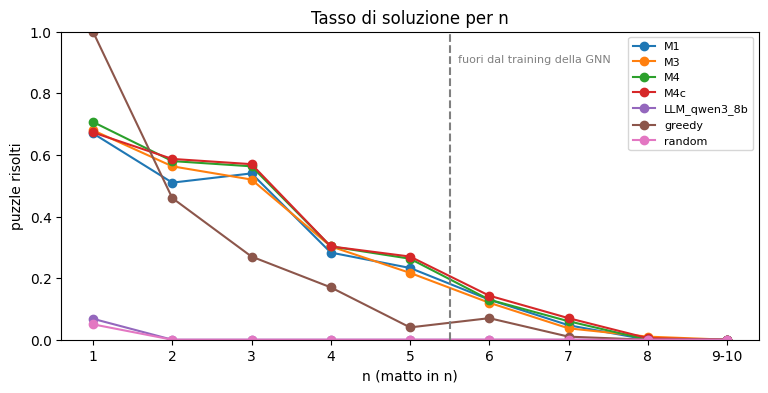

Prima mossa corretta:


gruppo,1,2,3,4,5,6,7,8,9-10
system,,,,,,,,,
M1,0.647,0.617,0.690,0.507,0.513,0.453,0.277,0.500,0.381
M3,0.660,0.703,0.700,0.547,0.580,0.473,0.287,0.422,0.381
M4,0.683,0.677,0.713,0.517,0.613,0.497,0.277,0.422,0.429
M4c,0.657,0.677,0.687,0.530,0.590,0.523,0.323,0.407,0.333
LLM_qwen3_8b,0.068,0.117,0.041,0.100,0.060,0.140,0.080,0.250,0.000
greedy,0.980,0.460,0.530,0.420,0.410,0.410,0.400,0.471,0.381
random,0.050,0.050,0.030,0.030,0.040,0.060,0.030,0.074,0.000


In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
for s in show:
    ax.plot(ORDER, table.loc[s], marker="o", label=s)
ax.axvline(4.5, color="gray", linestyle="--")
ax.text(4.6, 0.9, "fuori dal training della GNN", fontsize=8, color="gray")
ax.set_xlabel("n (matto in n)"); ax.set_ylabel("puzzle risolti"); ax.set_ylim(0, 1)
ax.set_title("Tasso di soluzione per n"); ax.legend(fontsize=8)
plt.show()

print("Prima mossa corretta:")
(allr[allr.system.isin(show)].groupby(["system", "gruppo"])["first_ok"].mean()
 .unstack()[ORDER].loc[show].round(3))

## 6. GNN vs LLM per n (McNemar)

Come nella parte 2: per la GNN (M4) un puzzle conta come risolto se lo risolvono almeno 2 seed su 3. Per il gruppo 9-10 il test ha pochissima potenza.

In [10]:
gnn = allr[allr.system == "M4"].groupby("case")["solved"].mean() >= 2 / 3
rows = []
for name in sorted(s for s in allr.system.unique() if s.startswith("LLM_")):
    L = allr[allr.system == name].set_index("case")
    for grp in ORDER:
        cases = L.index[L["gruppo"] == grp]
        g, l = gnn.loc[cases], L.loc[cases, "solved"]
        only_g, only_l = int((g & ~l).sum()), int((~g & l).sum())
        p = binomtest(only_g, only_g + only_l).pvalue if only_g + only_l > 0 else 1.0
        win = "pari" if p >= 0.05 else ("GNN" if only_g > only_l else "LLM")
        rows.append({"LLM": name, "n": grp, "puzzle": len(cases), "GNN": round(g.mean(), 3),
                     "LLM risolti": round(l.mean(), 3), "solo GNN": only_g, "solo LLM": only_l,
                     "p": p, "vince": win})
pd.DataFrame(rows)

,LLM,n,puzzle,GNN,LLM risolti,solo GNN,solo LLM,p,vince
0,LLM_qwen3_8b,1,88,0.705,0.068,58,2,3.176279e-15,GNN
1,LLM_qwen3_8b,2,94,0.564,0.000,53,0,2.220446e-16,GNN
2,LLM_qwen3_8b,3,98,0.561,0.000,55,0,5.551115e-17,GNN
3,LLM_qwen3_8b,4,100,0.300,0.000,30,0,1.862645e-09,GNN
4,LLM_qwen3_8b,5,100,0.270,0.000,27,0,1.490116e-08,GNN
5,LLM_qwen3_8b,6,100,0.140,0.000,14,0,1.220703e-04,GNN
6,LLM_qwen3_8b,7,100,0.050,0.000,5,0,6.250000e-02,pari
7,LLM_qwen3_8b,8,68,0.000,0.000,0,0,1.000000e+00,pari
8,LLM_qwen3_8b,9-10,21,0.000,0.000,0,0,1.000000e+00,pari


## Note per il report

- Per n ≥ 6 la GNN è **fuori distribuzione**: un calo va letto come limite di generalizzazione più che come limite dell'approccio. Per misurare il limite "vero" bisognerebbe riallenare includendo n = 6–8 (ci sono circa 1.100 puzzle con n = 6–8 disponibili, pochi per un training a sé).
- Lunghezza e difficoltà crescono insieme (rating medio da circa 1000 a n = 1 a circa 2300 a n = 8).
- Il gruppo 9-10 contiene pochi puzzle: va presentato come indicazione, non come risultato statistico.
- La traccia parlava di "problemi classici". Abbiamo usato puzzle Lichess lunghi perché hanno lo stesso formato e una soluzione verificata; i problemi composti classici hanno caratteristiche diverse (mosse chiave "silenziose", posizioni artificiali) e richiederebbero un adattamento della valutazione.